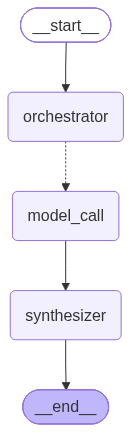

# 引言：为什么缩放定律重要

## 规模问题：参数、数据与算力

大语言模型的能力提升，在很大程度上由三个可度量的要素共同驱动：模型参数规模、训练数据规模与训练算力。这三者并非彼此独立——在给定的算力预算下，参数与数据之间存在此消彼长的权衡关系；而算力投入又决定了可用的参数量与数据量上限。正因如此，"规模"不再只是一个工程指标，而成为训练决策的核心变量：增加参数是否仍能带来等比例的损失下降？在固定算力下应优先扩充模型还是扩充数据？训练应在何处停止才最具成本效益？这些问题直接关系到数以千万美元计的算力开支能否转化为可预期的模型性能。

## 缩放定律作为经验性预测工具

缩放定律（Scaling Laws）正是回应上述问题的经验性工具。它通过对小规模训练实验的损失曲线进行拟合，刻画模型损失随参数量、数据量与算力变化的幂律关系，从而在投入巨额算力之前对大规模训练的最终性能做出预测。其核心价值体现在三个方面：其一，**预测能力**——在正式训练前估计目标规模下的损失水平，降低大规模训练的不确定性；其二，**资源分配指导**——在固定算力约束下给出参数与数据的最优配比，避免"大模型小数据"或"小模型大数据"造成的算力浪费；其三，**决策边界划定**——为训练是否继续、规模是否值得扩张提供量化依据。需要强调的是，缩放定律是经验规律而非理论定律，其外推有效性依赖拟合区间与训练配置的相似性，这一局限本身也是理解其价值边界的关键。

## 报告结构与范围界定

本报告聚焦**预训练阶段**的损失预测，系统梳理缩放定律的形式、拟合方法与实证发现，并在此基础上兼及两个延伸议题：一是缩放定律所预测的预训练损失与下游任务能力之间的关系（即"涌现"与能力可预测性问题），二是推理侧的缩放（inference-time scaling）对传统训练缩放框架的补充与挑战。报告不涉及微调、对齐训练的具体缩放规律，亦不展开硬件层面的算力优化细节。通过这一范围界定，本报告旨在为训练决策者提供一份关于缩放定律"能预测什么、如何预测、预测边界何在"的实用参考。

---

## 缩放定律的基本概念与数学形式

### 核心术语定义

缩放定律研究模型性能随规模变化的规律，其分析建立在四个核心量之上。**模型参数量 N** 指网络中可训练参数的总数，是衡量模型容量的基本指标；**训练数据量 D** 指训练过程中消耗的 token（或样本）总数；**计算量 C** 指训练所消耗的浮点运算次数（FLOPs），是连接 N 与 D 的预算约束量；**不可约损失 L∞** 指当模型与数据规模趋于无穷时损失收敛的下界，反映了任务本身固有的熵或噪声水平，无法通过增大规模消除。

### 幂律形式的通用表达

缩放定律的经验形式通常表述为幂律加常数项的结构：

L(N, D) = E + A/N^α + B/D^β

其中 E 对应不可约损失（即 L∞），A/N^α 刻画模型容量不足带来的损失，B/D^β 刻画数据不足带来的损失，α、β 为对应的幂律指数，A、B 为拟合系数。该表达的直觉在于：损失由三部分组成——任务固有下界、有限参数导致的近似误差、有限数据导致的估计误差，两部分误差均随规模增大而按幂律衰减。这一形式具有可分离性，便于分别考察参数与数据两个维度的贡献，也解释了为何单纯增大 N 或单纯增大 D 都会遇到边际收益递减。

### 计算预算约束

训练总计算量与参数量、数据量近似满足线性关系：

C ≈ 6ND

其推导基于 Transformer 类模型的前向与反向传播开销：每个参数对每个 token 的前向计算约为 2 次浮点运算（一次乘加），反向传播约为前向的 2 倍，合计约 6 次。因此 C ≈ 6ND 给出了在给定算力预算下 N 与 D 的权衡边界——增大 N 必须相应减少可处理的 D，反之亦然。该约束是"计算最优"（compute-optimal）分配问题的核心：在 C 固定的条件下最小化 L(N, D)，可解得 N 与 D 的最优比例，这一结论直接指导了训练配比的实践决策。

### 损失缩放与能力缩放

缩放定律的研究对象可区分为两类。**损失缩放**关注连续指标（如交叉熵损失）随规模的幂律下降，其曲线光滑、易于拟合，是构建定量预测的基础。**能力缩放**关注离散或任务级指标（如下游准确率、基准通过率）随规模的变化，这类指标往往呈现非线性、阈值式或涌现式行为，难以用简单幂律描述。

指标选择带来显著差异：交叉熵作为平滑的代理指标，能稳定反映规模收益并支持外推预测；而下游准确率受任务难度、评测方式、指标饱和等因素影响，可能出现"损失持续下降但准确率平台化"或"损失平缓但能力突现"的现象。因此，缩放定律的定量结论多以损失为对象建立，向能力指标的迁移需谨慎处理，二者不可简单等同。

---

# 经典工作演进：从 Kaplan 到 Chinchilla

## 一、Kaplan 等人（2020）：早期缩放定律

Kaplan 等人（2020）的《Scaling Laws for Neural Language Models》首次系统性地刻画了语言模型损失与模型规模、数据规模、计算量之间的幂律关系。其核心发现是：测试损失随参数量 \(N\)、数据量 \(D\)、计算量 \(C\) 均呈幂律下降，且在不同规模下呈现高度可预测性。

该工作最重要的实践推论是**"优先扩大参数量"**：在固定计算预算下，Kaplan 等人建议将大部分新增计算分配给模型参数，而数据量的增长应相对缓慢（其建议约为每参数 1.7 个 token 量级）。这一结论直接影响了 GPT-3 等模型的设计取向——参数量被推到极致，而训练 token 数相对受限。

## 二、Chinchilla（Hoffmann 等，2022）：计算最优配比的重估

Hoffmann 等人（2022）的《Training Compute-Optimal Large Language Models》对上述结论进行了系统性重估。通过训练 400 余个不同规模（70M 至 16B 参数）的模型并采用三种独立拟合方法，作者得出：**参数量与训练数据量应大致同比例增长**，计算最优配比约为每参数 20 个 token。

这一修正意味着，同等计算预算下应训练"更小但见更多数据"的模型。Chinchilla（70B 参数、1.4T token）在多数基准上超越了参数量大 4 倍的 Gopher（280B），以实证方式验证了配比修正的有效性。相较 Kaplan 的建议，Chinchilla 将数据量的相对权重提高了约一个数量级。

## 三、两者差异的成因分析

两项工作的结论分歧并非源于基本幂律形式，而主要来自以下方面：

1. **学习率调度**：Kaplan 等人使用固定学习率并训练至收敛，而 Chinchilla 采用余弦调度，使不同规模模型的训练更充分，改变了损失—规模关系的估计。
2. **数据规模与重复**：Kaplan 的实验在部分配置下存在数据重复或数据量不足的问题，影响了数据项的边际收益估计；Chinchilla 显式控制数据量并避免重复。
3. **拟合方法**：Kaplan 采用单一拟合流程，对参数量与数据量的权衡估计较为敏感；Chinchilla 采用三种方法（固定模型拟合、IsoFLOP 剖面、参数化拟合）交叉验证，结论更稳健。
4. **实验网格覆盖**：Chinchilla 的实验网格更宽、更均匀，减少了外推误差。

## 四、对业界训练范式的改变

Chinchilla 的修正显著改变了业界的训练范式：

- **数据成为一等公民**：训练 token 数从"配角"变为与参数量并列的核心设计变量，数据采集、清洗与配比工程的重要性大幅上升。
- **"小模型 + 多数据"成为主流**：同等算力下优先扩大数据，催生了 LLaMA 系列等以远超 20 tokens/参数比例训练的模型（如 LLaMA 2 使用 2T token 训练，远超 Chinchilla 最优）。
- **推理成本纳入考量**：由于部署成本随参数量增长，业界在实际决策中常主动偏离计算最优配比，偏向更小模型以降低推理开销。

## 五、后续相关工作

Chinchilla 之后，研究进一步拓展了缩放定律的边界：

- **数据受限场景下的重复训练**：Muennighoff 等人（2023）的《Scaling Data-Constrained Language Models》研究了当高质量数据不足时的重复训练（multi-epoch）策略，发现适度重复（约 4 个 epoch 内）的收益衰减有限，为数据受限条件下的配比决策提供了依据。
- **推理感知的缩放**：后续工作将推理成本纳入优化目标，提出"过训练"（over-training）策略——以超出 Chinchilla 最优的数据比例训练小模型，换取部署效率。
- **数据质量与配比**：研究逐渐从"数据量"转向"数据质量"，如去重、过滤与课程配比对缩放曲线的调节作用。

综上，从 Kaplan 到 Chinchilla 的演进体现了缩放定律从"参数优先"到"参数—数据均衡"的范式转变，而后续工作则在数据受限与推理成本约束下继续细化这一框架。

---

# 影响缩放行为的其他关键因素

## 模型架构：稠密与混合专家

在 N 与 D 之外，架构选择是改变缩放曲线形态的首要变量。稠密 Transformer 的缩放行为已被较充分地刻画，而混合专家（MoE）模型通过条件计算将参数量与每 token 计算量解耦：总参数量 N 的增长不再线性对应 FLOPs 的增长，使得以计算量为横轴的缩放曲线在指数与截距上都发生偏移。实践中，MoE 在相同计算预算下往往获得更低的损失，但其缩放收益依赖于专家数量、路由策略与负载均衡质量；路由退化或专家利用率不足会削弱甚至逆转这一优势。这表明"参数量—损失"关系并非架构无关，稠密与稀疏模型需要各自的缩放参数化。

## 数据质量与去重

数据质量是改变缩放曲线截距的强效杠杆。经质量过滤与去重的语料，在相同 token 预算下产生系统性更低的损失，等效于放大了有效数据量 D_eff；反之，重复数据与低质样本会使缩放曲线提前进入收益递减区间。去重的意义不止于节省算力：重复暴露会改变模型对数据的有效利用方式，使经验缩放指数偏离干净数据下的估计。因此，以原始 token 数计量的 D 必须辅以质量与重复度校正，否则跨数据集的缩放定律比较缺乏可比性。

## 数据分布与领域配比

领域配比决定了缩放曲线在不同分布上的位置与斜率。代码、数学、多语言与自然文本具有不同的学习难度与熵特性，配比变化会同时移动整体损失水平与各领域的收敛速度。更重要的是，混合分布下的缩放行为不能简单由各领域缩放曲线的加权平均得到：领域间存在迁移与干扰，配比失衡可能导致整体曲线在某一规模后出现斜率变化。这使缩放定律具有分布依赖性——在某一配比下拟合的指数，未必可外推至另一配比。

## 词表与分词

分词器通过改变序列长度与 token 的语义密度，间接重塑 D 与计算量的对应关系。更大的词表压缩序列、降低每 token 计算成本，但会稀释单个 token 的信息量并增加嵌入与输出层的参数负担；较小的词表则相反。跨语言与跨模态场景下，分词效率的差异尤为显著，可能导致同一模型在不同语言上呈现不同的有效缩放轨迹。词表选择因此是缩放曲线参数化的隐性变量，跨分词器比较损失值时须格外谨慎。

## 优化器与学习率调度

优化器族与超参数调度影响的是缩放曲线的可达性而非仅其位置。Adam 类优化器、Muon 等新方法的对比显示，在相同预算下可获得更低的损失或更陡的下降斜率；而学习率、批大小与预热/衰减调度若未随规模适配，会使大模型落在次优曲线上，表现为表观指数的偏移。所谓"缩放定律"通常隐含超参数随规模调优的前提；超参数迁移的失效是跨规模外推误差的重要来源。

## 长上下文

上下文长度扩展引入了新的计算与数据维度。长上下文训练改变注意力计算的结构性成本，也使有效数据利用方式发生变化：序列打包、注意力模式与位置编码设计共同影响模型在长依赖任务上的缩放行为。长上下文能力往往呈现非平滑的规模依赖，其缩放曲线难以由短上下文结果直接外推。

## 涌现与相变现象

部分能力随规模呈现非线性跃升而非平滑改善，即所谓"涌现"。这类现象对缩放定律构成概念挑战：若下游指标在某一规模附近发生相变，则以平滑幂律拟合的曲线无法预测该转折。争论集中于度量选择（连续指标 vs. 离散阈值指标）与相变是否源于指标构造；无论结论如何，它都提示缩放定律的适用边界依赖于所预测的目标量，平滑外推对某些能力并不可靠。

## 推理侧缩放

测试时计算、思维链与采样搜索构成了独立于训练规模的新缩放维度。增加推理计算可在固定模型上提升答案质量，其收益曲线同样遵循幂律式递减，且与训练规模存在交互：更大的基座模型对推理计算的利用效率更高，而推理侧投入也可部分替代训练侧规模。这使"缩放"从单一的训练轴扩展为训练—推理的二维权衡，传统以 N、D 为核心的定律需纳入推理计算量才能完整描述性能前沿。

## 缩放定律的非普适性

综合上述因素，缩放定律并非普适物理规律，而是特定架构、数据分布、分词方案与优化配置下的经验正则性。架构改变参数化，数据质量与配比改变有效 D 与曲线斜率，优化与调度决定曲线可达性，长上下文与推理计算引入新维度，涌现现象则划定平滑外推的边界。因此，缩放定律的可靠用法是在明确条件下拟合、在条件变化时重新校准，而非跨设定直接套用指数与截距。

---

# 缩放定律的实证方法与拟合实践

## 一、小规模实验设计：模型尺寸 × 数据量网格

拟合缩放定律的第一步是构建一个结构化的实验网格。典型做法是选择若干模型尺寸（如 10M、30M、100M、300M 参数）与若干数据量水平（如 1B、3B、10B、30B token），形成二维网格，在每个格点上独立训练并记录最终损失。

设计要点：

- **网格覆盖范围要足够宽**：参数跨度和数据跨度最好各达到一个数量级以上，否则幂律指数难以稳定辨识。经验上至少 3×3 网格，推荐 4×4 或更大。
- **学习率需按尺寸分别调优**：不同规模模型的最优学习率不同，若统一使用一个学习率，小模型可能欠拟合、大模型可能发散，导致拟合出的指数失真。常见做法是对每个尺寸单独做短程学习率扫描。
- **固定其他超参数配方**：除学习率外，batch size、warmup 比例、权重衰减等应尽量保持一致或按已知规律缩放，避免引入与规模无关的噪声。
- **记录完整的训练曲线而非仅终点损失**：中途损失对后续外推与早停预测至关重要。

## 二、训练中途损失外推

完整训练大模型成本高昂，实践中常利用早期训练曲线外推最终损失。常用形式包括：

- **幂律衰减拟合**：对损失随步数的下降拟合 \(L(t) = L_\infty + a t^{-\alpha}\)，其中 \(L_\infty\) 为渐近损失估计。该形式在训练中后期较稳定，但早期拟合偏差较大。
- **对数线性外推**：在半对数坐标下对中后段曲线做线性拟合并外推，简单但外推距离有限。
- **多曲线联合约束**：将不同尺寸模型的曲线联立，共享部分参数（如指数），可显著提升外推稳定性。

关键实践：外推窗口应避开 warmup 阶段与学习率衰减末期；建议用留出步数做验证，比较外推预测与真实终点的偏差，偏差过大时不应直接采用外推值。

## 三、拟合优度评估与置信区间

拟合完成后必须评估拟合质量，而非仅报告点估计：

- **残差分析**：检查残差是否随规模呈现系统性趋势。若残差在小模型端偏正、大模型端偏负，说明函数形式或指数设定有误。
- **留一法交叉验证**：依次留出一个网格点，用其余点拟合并预测被留出点，统计预测误差分布，这是最直接的泛化能力检验。
- **参数置信区间**：通过 bootstrap 重采样或拟合协方差矩阵估计指数与系数的置信区间。指数的不确定性往往比点估计更值得关注——若指数置信区间过宽，外推结论不可靠。
- **报告拟合优度指标**：如 \(R^2\)、RMSE，并明确说明是在哪个规模区间内拟合的。

## 四、外推风险的来源

缩放定律的外推本质上是函数形式的假设，风险主要来自：

- **分布漂移**：训练数据分布、数据质量过滤策略或数据混合比例在小规模与大规模型之间不一致时，拟合关系会在规模外失效。小规模实验应尽量复用目标大模型的同一数据管线。
- **超参数未调优**：若大模型使用与小模型不同的最优学习率、batch size 或训练时长比例，幂律关系会被打破。外推前应确认超参数随规模的缩放规则已被覆盖。
- **数值精度**：低精度训练（如 bf16 累积误差）、不同优化器实现、不同框架版本都可能引入系统性偏差，尤其在极小模型上噪声占比更高。
- **架构或分词器变化**：跨架构、跨词表外推几乎必然失效，缩放定律只在同一模型族内可信。

## 五、可解释的替代方法

当纯幂律外推风险较高时，可考虑以下替代或补充手段：

- **学习曲线早停预测**：基于已观察的训练曲线形态预测"还需多少 token 才能达到目标损失"，用于训练预算分配与早停决策，不依赖跨规模外推假设。
- **功能性缩放（functional scaling）**：用带更多自由度的函数形式（如加入饱和项、双幂律项）拟合，捕捉收益递减的转折点，比单一幂律更具解释性，但需更多数据点支撑，避免过拟合。
- **分区间拟合**：在不同规模区间分别拟合，明确标注每个区间适用的结论，避免用单一公式覆盖所有规模。

## 六、工程师视角的实操建议与常见陷阱

**建议：**

1. 先做 3×3 最小网格跑通全流程，验证数据管线与评估一致性，再扩大网格。
2. 每个尺寸至少单独调一次学习率，哪怕只是短程扫描；这是拟合质量的最大杠杆。
3. 保留原始训练日志与曲线，所有外推结论都应可回溯到具体实验配置。
4. 把外推预测与留出点实测做对照，形成"预测—验证"闭环，持续校准。
5. 明确区分"用于规划的粗略估计"与"用于决策的精确预测"，前者可用幂律外推，后者需交叉验证支撑。

**常见陷阱：**

- 用单一学习率跑所有尺寸，导致指数被系统性扭曲。
- 只拟合终点损失、忽略训练曲线，错过早停预测与异常检测的机会。
- 在 warmup 或学习率衰减阶段的数据上做外推，得到虚假的渐近损失。
- 网格点太少（如 2×2）导致拟合自由度不足，置信区间失去意义。
- 跨数据配方、跨架构复用拟合系数，忽略分布漂移。
- 只报告点估计而不报告置信区间，让外推结论显得比实际更确定。

---

## 缩放定律的局限、争议与批判

### 一、幂律外推的可靠性问题

缩放定律的核心承诺在于：通过在较小规模上拟合的幂律关系，可以预测更大模型、更多数据、更多算力下的损失表现。然而，这一外推策略的可靠性始终面临根本性质疑。幂律拟合通常仅在有限范围内成立，当规模跨越数个数量级时，曲线可能发生斜率变化、饱和甚至反转。Kaplan 等（2020）与 Hoffmann 等（2022）的研究虽然均支持幂律趋势，但两者在最优算力分配策略上的结论存在显著差异——前者主张优先扩大模型参数，后者则认为应同步扩大数据量——这本身即说明幂律的具体形式对实验设置、拟合区间和度量方式高度敏感。更关键的是，外推所依赖的"规模不变性"假设缺乏理论保证：损失曲面在不同规模下的几何结构可能发生质变，使得小规模实验所揭示的规律无法可靠迁移至大规模区间。此外，缩放定律通常以预训练交叉熵损失为预测目标，而这一指标与模型的实际能力之间并非一一对应，外推所得的损失预测能否转化为对下游性能的有效预期，仍是一个未决问题。

### 二、"涌现能力"是否为度量假象

关于大模型"涌现能力"的讨论构成了缩放定律争议的焦点之一。Wei 等（2022）将涌现能力定义为在小模型中不可见、而在规模超过某一阈值后突然出现的能力，并以此作为缩放带来质性跃迁的证据。然而，Schaeffer 等（2023）对此提出了系统性批判：他们指出，所谓"涌现"在很大程度上是度量选择所制造的假象。当研究者采用不连续、非线性或阈值化的评价指标（如精确匹配准确率）时，模型性能随规模的变化会呈现出看似突变的跳跃；而若改用连续、平滑的度量（如 token 级对数似然或编辑距离），则同样的模型规模序列会表现出平滑渐进的改善。这意味着"涌现"并非模型能力发生了本质性的相变，而是评价指标的分辨率与非线性变换所致。这一批判动摇了将缩放定律与"能力跃迁"直接挂钩的叙事，也提示学界在宣称某能力"涌现"时必须审慎选择并报告多维度度量。围绕该问题的争论至今未息：支持涌现真实性的研究者认为，某些任务上的阈值行为在多种度量下均稳健存在，且具有实践意义；批评者则坚持，在缺乏理论机制解释的情况下，"涌现"标签容易导致对缩放规律的过度解读。

### 三、损失下降与下游任务表现的不一致

缩放定律以损失为因变量，但损失下降与下游任务表现之间的映射关系远非单调可靠。大量实证表明，预训练损失的持续改善并不必然转化为下游基准的同步提升：在某些任务上，损失的小幅下降伴随下游准确率的大幅跃升；在另一些任务上，损失显著降低而下游表现停滞甚至退化。这种不一致源于多重因素：下游任务往往涉及分布偏移、指令遵循、推理链组织等预训练损失未能直接刻画的维度；损失度量对 token 分布中的高频模式更为敏感，而下游能力可能依赖于低频但关键的语言现象；此外，微调与提示策略的差异也会放大或掩盖预训练损失与下游表现之间的关联。这一不一致性从根本上削弱了缩放定律的实践指导价值——即便幂律对损失的预测准确无误，决策者真正关心的是特定应用场景中的能力表现，而后者无法由损失外推直接获得。近年来的研究尝试建立损失与下游性能之间的 scaling law（如 Gadre 等，2024），但其适用范围和稳健性仍有待检验。

### 四、数据枯竭与高质量数据上限

缩放定律的另一支柱是数据量的可扩展性。Chinchilla 最优配置表明，模型性能随训练 token 数呈幂律改善，这隐含地假设高质量数据可以持续供给。然而，现实约束正在收紧：公开互联网中高质量文本的存量有限，且已被大规模爬取；数据过滤与去重虽能提升质量，却也缩小了可用池；版权、隐私与许可限制进一步压缩了合规数据的获取空间。Villalobos 等（2024）估计，若维持当前的数据消耗增速，高质量语言数据可能在数年内面临实质性枯竭。数据枯竭不仅威胁缩放定律外推的前提，也改变了算力-数据-参数的最优配置逻辑：当数据成为瓶颈时，单纯增加参数量或算力的边际收益将递减，而数据效率、合成数据与重复训练策略的重要性相应上升。合成数据虽被视为潜在解方，但其质量退化、多样性不足与分布偏移等问题尚未解决，能否支撑幂律的持续成立仍存疑问。

### 五、能源与成本约束

缩放定律在物理层面面临能源与成本的硬约束。训练前沿模型的算力需求呈指数增长，对应的电力消耗、散热需求与资本支出同步攀升。训练成本的高企不仅限制了可参与前沿缩放的主体数量，也使得"以更大规模换取更低损失"的经济性受到质疑：当边际损失改善所需的算力投入呈幂律增长时，单位性能提升的成本迅速膨胀，而收益（下游能力改善）却未必成比例增长。推理阶段的成本同样不容忽视——更大模型意味着更高的部署开销，这在商业可行性上构成实质性约束。能源方面，数据中心的供电容量、碳排放目标与电网接入限制正在成为规模化训练的瓶颈。这些约束共同表明，缩放定律所描述的"规模-性能"关系即使在技术上成立，也在经济与环境层面遭遇不可忽视的边界。

### 六、"缩放不再是唯一路径"

在上述局限的综合作用下，"缩放是唯一路径"的观点受到越来越多的挑战。架构创新（如稀疏混合专家、状态空间模型、检索增强）、合成数据与数据课程设计、后训练与对齐技术（指令微调、偏好优化、推理时计算扩展）的重要性显著上升。这些路径的共同特点在于：它们试图在不单纯依赖规模扩张的前提下提升能力，或改变规模投入的配置方式。值得注意的是，部分新路径本身仍呈现缩放行为——例如推理时计算扩展（Wu 等，2024）表明性能随推理算力呈幂律改善——因此并非对缩放定律的否定，而是对其适用维度的拓展。然而，这些路径也引入了新的不确定性：合成数据可能引发模型崩溃，对齐技术的效果难以跨场景泛化，架构创新的收益往往与特定任务绑定。总体而言，学界与工业界的共识正在从"缩放万能"转向"缩放必要但非充分"，多路径协同成为更具现实基础的战略取向。

### 七、学术界与工业界的结论分歧及其原因

围绕缩放定律的争议，学术界与工业界呈现出系统性分歧。工业界实验室凭借前沿规模的实验条件，往往报告缩放规律持续有效、并可外推至更大规模的乐观结论；学术界则因算力受限，更多依赖小规模实验与理论分析，倾向于揭示幂律的适用边界、度量假象与外推风险。分歧的成因是多层次的：其一，**证据基础不对称**——工业界掌握大规模训练的内部数据，其结论难以被独立复现，而学术界的批判也多基于有限规模的代理实验；其二，**激励结构差异**——工业界的缩放叙事与资本投入、产品路线图相互绑定，学术界的批判则受同行评议对新颖性与严谨性的偏好驱动；其三，**度量与目标错位**——工业界关注产品级能力与基准表现，学术界关注损失的可预测性与机制的可解释性，双方在"什么算作缩放定律成立"上缺乏共同的操作定义；其四，**发表偏差与选择性报告**——成功的缩放外推更易被公开，失败的规模化尝试则较少披露。弥合分歧需要更透明的实验报告规范、可复现的中等规模基准，以及对损失-能力映射关系的共同研究议程。

---

# 对研究与产业实践的意义

缩放定律的价值不在于给出一个精确的预测公式，而在于提供一套可操作、可校准、可证伪的决策框架。它将模型性能与算力、数据、参数量之间的经验关系显式化，使研究与产业实践中的资源配置从"凭直觉押注"转向"带误差棒的外推"。以下从六个实践维度展开，并讨论如何在不确定环境中把它当作决策工具而非教条。

## 预算分配与算力规划

缩放定律最直接的产业影响是改变了预算分配的逻辑。在算力受限时，核心问题不再是"要不要做大"，而是"在给定总算力下，参数量与数据量如何配比才最优"。Chinchilla 的工作表明，在固定计算预算下，模型参数量与训练 token 数应大致按比例同步增长，此前"参数越大越好、数据尽量少"的实践存在系统性偏离。这一结论直接重塑了训练预算的切分方式：算力预算需要在模型规模、数据规模与训练时长之间做显式权衡，而非把大部分预算压在参数扩张上。

在规划层面，缩放定律使"算力—性能"曲线可以被外推，从而支持多年度算力规划的论证。团队可以在小规模实验上拟合幂律指数，再外推到目标算力，估算达到某一损失水平所需的资源量级，并据此申请预算或设定阶段目标。关键在于外推必须附带不确定性区间，且拟合点应覆盖足够宽的范围，避免用单点推断。

## 模型尺寸选择与产品定位

缩放定律把模型尺寸选择从"能力崇拜"拉回到"边际收益核算"。幂律意味着性能随规模提升但边际递减，因此产品定位应回答：目标场景需要多低的损失？超出该阈值的算力投入是否带来可感知的产品收益？对于延迟敏感、成本敏感的推理场景，过大的模型可能带来负向收益，此时缩放定律提供的"损失—规模"曲线应与推理成本曲线联合使用，寻找总拥有成本最优的规模点。

这也解释了产业中"小模型 + 高质量数据 + 蒸馏"路线的合理性：若数据质量或训练配方能改变幂律的系数甚至指数，则同等算力下可达到更低的损失，尺寸选择就不应只由参数量决定，而应由"有效算力效率"决定。

## 训练早停与失败预警

缩放定律为训练过程提供了预期损失的参照基线。在训练早期，用小规模学习率扫描或短程训练拟合损失下降轨迹，可以与缩放定律预测的轨迹比对：若实际损失显著高于同算力下的预期，往往预示数据质量、优化器配置或数值稳定性存在问题，构成早期失败预警信号。反之，若损失下降明显快于预期，则可能提示数据泄漏或评估污染。

早停决策同样可以量化：当继续训练的边际损失下降已低于目标精度所需，或相对于总算力预算的边际收益趋近于零时，停止训练并把资源转向数据或下一轮迭代，比盲目跑满预算更合理。这里的关键是把"预期损失曲线"作为监控对象，而非只看绝对损失值。

## 数据采集策略的量化依据

缩放定律把数据从"越多越好"的模糊直觉转化为可计算的投入项。在给定算力下，最优 token 数可以被估算，从而为数据采集规模设定下界与上界：采集不足会浪费算力，采集过量则边际价值低且带来清洗与存储成本。更重要的是，数据质量可以视为改变幂律系数的因素——重复数据、低质数据会抬高达到同一损失所需的 token 数，这为"去重、过滤、配比"的投入提供了量化依据：数据工程的收益可以用"等效 token 节省"来衡量。

实践中，这意味着数据策略应与模型规模协同规划，而非在模型确定后再补数据；数据配比实验也应设计成可拟合的形式，以便估计不同数据源对损失的边际贡献。

## 硬件与集群设计

缩放定律的实践约束最终落在硬件与集群设计上。大规模训练的瓶颈往往不在峰值算力，而在内存墙与通信开销：参数量增长使模型状态、激活与优化器状态的内存需求线性或超线性上升，单卡容量与带宽成为硬约束，迫使采用张量并行、流水并行与数据并行的组合；而并行度提高又放大通信开销，使有效算力利用率随规模下降。缩放定律若忽略这些系统性开销，就会高估大规模训练的可行性。

因此，集群设计应把"有效算力"而非"标称算力"作为规划单位，并在缩放拟合中显式计入通信与内存约束带来的效率折损。互连拓扑、显存容量、带宽与故障率共同决定了某一规模点是否经济可行，这反过来约束了模型尺寸与并行的选择。

## 在不确定环境中作为决策工具而非教条

把缩放定律当教条的风险有三：其一，幂律是在特定数据分布、架构与训练配方下拟合的经验关系，跨分布外推可能失效；其二，指数与系数的估计本身带有较大误差，尤其在小规模拟合点稀疏时；其三，缩放定律描述的是损失，而产品关心的是下游任务表现，二者关系并非总是一致。

作为决策工具，正确用法是：把缩放定律视为带不确定性的先验，用小规模消融实验持续校准系数；把外推结果表达为区间而非点估计，并据此做鲁棒决策（例如选择在悲观情形下仍可接受的规模）；对改变幂律系数的因素（数据质量、架构改进、训练配方）保持敏感，把它们当作"移动曲线"的杠杆而非曲线的反例；同时保留对下游指标的独立评估，避免用损失曲线替代产品验证。案例上，Chinchilla 对"参数—数据"配比的修正、以及后续工作中对数据质量改变缩放效率的观察，都说明缩放定律的价值在于它可被实验修正——一个能被证伪并被更新的决策框架，才是它在不确定环境中最可靠的用法。

---

## 未来方向与结论

### 展望

**数据受限与合成数据条件下的缩放规律。** 当前缩放定律的拟合大多建立在充足、高质量自然数据可得的假设之上，而这一前提正日益受到挑战。当高质量语料接近枯竭时，缩放关系是否依然成立、以何种形式成立，成为亟待回答的问题。合成数据提供了一条潜在的补充路径，但其引入也带来分布偏移、模式坍缩与误差累积等风险。未来研究需要刻画混合数据（自然数据与合成数据）条件下损失随数据量与模型规模变化的联合规律，明确合成数据的有效替代率及其随规模变化的稳定性边界。

**多模态与推理计算的联合缩放。** 现有缩放定律主要针对单一文本模态与单次前向计算。多模态输入（图像、音频、视频等）引入新的维度，各模态的token化方式、信息密度与缩放效率可能存在显著差异；推理时计算（如思维链、采样与搜索）则把“推理深度”纳入缩放变量。如何构建同时涵盖模型参数、训练数据、模态构成与推理计算量的多维缩放框架，并识别各维度之间的替代与互补关系，是下一阶段的核心议题。

**超出幂律的机制性理解。** 幂律是经验拟合的产物，其指数来源缺乏理论解释。仅凭幂律外推，难以判断规律在更大规模下是否失效、何时失效。未来需要从机制层面解释缩放指数的来源——例如将其与数据的内在维度、任务的可分解性、表示学习的样本复杂度等理论量联系起来，从而把“拟合曲线”推进为“可解释的预测”。这也有助于识别幂律之外的相变或饱和现象。

**规模化评估与安全性随规模的变化。** 能力随规模提升的同时，评估本身也在规模化：基准污染、评估成本与评估效度问题随模型增大而加剧。更关键的是，安全性相关属性（如有害输出倾向、欺骗行为、可控性）是否随规模呈现系统性变化，目前证据有限且结论不一。未来需要建立可随规模扩展的评估方法学，并将安全指标纳入缩放分析框架，而非作为事后附加的检查项。

### 结论

本报告的核心观点是：**缩放定律是强大但条件性的经验工具。** 其强大之处在于，在给定架构族、数据分布与训练流程的条件下，它能以少量实验对更大规模的表现作出有信息量的外推，从而显著降低规模化决策的成本与不确定性。其条件性在于，幂律系数与指数高度依赖于架构选择、数据质量与配比、token化方式以及后训练策略，跨条件的简单外推往往失效。

因此，缩放定律不应被视作独立的“规模万能论”，而必须与架构创新、数据工程和后训练共同使用：架构决定缩放曲线的形状与效率，数据工程决定曲线在何处开始饱和，后训练则决定规模所积累的能力能否转化为实际可用的性能与安全性。唯有将三者纳入统一的实验与理论框架，缩放定律才能从描述性的经验规律，发展为可靠的规模化决策依据。

In [1]:
from typing import Annotated, List, TypedDict
from collections.abc import Sequence
from langchain_core.messages import SystemMessage, HumanMessage
from langgraph.graph import StateGraph, START, END
from langgraph.types import Send
from langchain_deepseek import ChatDeepSeek
from operator import add
from pydantic import BaseModel, Field

from dotenv import load_dotenv
load_dotenv(override=True)

model = ChatDeepSeek(
    model="deepseek-flash",
    extra_body={
        "thinking": {
            "type": "disabled"
        }
    }
)

# 结构化输出的 Schema
class Section(BaseModel):
    name: str = Field(
        description="报告的章节名称",
    )
    description: str = Field(
        description="本节主题和核心思想的概述",
    )

class Sections(BaseModel):
    sections: List[Section] = Field(
        description="报告的章节列表",
    )

# 编排器
planner = model.with_structured_output(Sections)

# 图状态
class OverAllState(TypedDict):
    topic: str  # 报告主题
    sections: list[Section]  # 报告章节列表
    completed_sections: Annotated[
        list, add
    ]  # 所有工作节点并行写入该字段
    final_report: str  # 最终报告


# 工作节点状态
class WorkerState(TypedDict):
    section: Section
    completed_sections: Annotated[list, add]

# 节点
def orchestrator(state: OverAllState) -> OverAllState:
    """编排器：生成报告编写计划"""

    # 生成报告章节规划
    report_sections = planner.invoke(
        [
            SystemMessage(content="为这份报告生成一个章节规划。"),
            HumanMessage(content=f"报告主题如下：{state['topic']}"),
        ]
    )

    return {"sections": report_sections.sections}

def model_call(state: WorkerState) -> WorkerState:
    """工作节点：编写报告中的一个章节"""

    # 生成章节内容
    section = model.invoke(
        [
            SystemMessage(
                content=(
                    "根据提供的章节名称和章节描述编写报告内容。"
                    "不要在每个章节前添加额外的开场说明。"
                    "使用 Markdown 格式。"
                )
            ),
            HumanMessage(
                content=(
                    f"章节名称：{state['section'].name}\n"
                    f"章节描述：{state['section'].description}"
                )
            ),
        ]
    )

    # 将生成的章节写入已完成章节列表
    return {"completed_sections": [section.content]}


def synthesizer(state: OverAllState) -> OverAllState:
    """将所有章节合成为完整报告"""

    # 获取所有已完成的章节
    completed_sections = state["completed_sections"]

    # 将已完成章节拼接为最终报告
    completed_report_sections = "\n\n---\n\n".join(completed_sections)

    return {"final_report": completed_report_sections}


# 条件边函数：为规划中的每个章节创建一个 model_call 工作节点
def assign_workers(state: OverAllState) -> Sequence[Send]:
    """为规划中的每个章节分配一个工作节点"""

    # 使用 Send API 并行启动各个章节的编写任务
    return [Send("model_call", {"section": s}) for s in state["sections"]]


# 构建工作流
builder = StateGraph(state_schema=OverAllState)

# 添加节点
builder.add_node("orchestrator", orchestrator)
builder.add_node("model_call", model_call)
builder.add_node("synthesizer", synthesizer)

# 添加边，连接各个节点
builder.add_edge(START, "orchestrator")
builder.add_conditional_edges(
    "orchestrator",
    assign_workers,
    ["model_call"],
)
builder.add_edge("model_call", "synthesizer")
builder.add_edge("synthesizer", END)

# 编译工作流
graph = builder.compile()

# 调用工作流
state = graph.invoke(
    {"topic": "撰写一份关于大语言模型缩放定律的报告"}
)

from IPython.display import Markdown, display

# 显示工作流图
display(graph)
# 渲染报告
Markdown(state["final_report"])